In [ ]:
import sys; sys.path.insert(0, '../../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [3]:
import warnings
warnings.filterwarnings('ignore')

import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from load_everything import *
from harness import *
import pickle

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )

from f2_utils import *
import time_in_each_roi
import matplotlib.patches as patches
import time_in_each_roi
from sklearn.linear_model import MultiTaskLassoCV,LassoCV
from sklearn.metrics import mean_squared_error,r2_score
from sklearn.model_selection import train_test_split


# make sure linear model and CNN use the same training data

In [4]:
# neural_root = '/home/wx2203/Weihao/data_locker/step_2/'
# rotary_root = '/home/wx2203/RS_analysis/H_b_new/'
# dlc_root = '/home/wx2203/RS_analysis/DLC/'
# whisk_dlc_root = '/home/wx2203/Weihao/analysis/DLC/'
# groom_dlc_root = '/home/wx2203/Weihao/behavior_locker/body_dlc/'
# config_root = '/home/wx2203/Weihao/data_locker/step_0/'
prefix = '/mnt/staging/'
fetch_path = str(PREPARES / "modeling") + "/"
mouse = 'cm125'
# motion_summary_root = prefix+'/users/wx2203/new_analysis_locker/motion_summary/'

In [5]:
data_joint = load_model(fetch_path+mouse+'_data_joint.pickle')

In [6]:
data_joint.columns[-10:]

Index([494, 495, 496, 497, 498, 499, 'face_pc', 'rotf', 'is_groom', 'LFP'], dtype='object')

In [7]:
def IsPointInROI(x1, y1, x2, y2, x, y) : 
    if (x > x1 and x < x2 and y > y1 and y < y2) : 
        return True
    else: 
        return False
def save_model(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file)

def load_model(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model
def set_level_values(midx, level, values):
    full_levels = list(zip(*midx.values))
    names = midx.names
    if isinstance(level, str):
        if level not in names:
            raise ValueError(f'No level {level} in MultiIndex')
        level = names.index(level)
    if len(full_levels[level]) != len(values):
        raise ValueError('Values must be of the same size as original level')
    full_levels[level] = values
    return pd.MultiIndex.from_arrays(full_levels, names=names)

In [5]:
# data_joint = load_model(f4_locker_root+mouse+'_data_joint.pickle')
# remove all runD
# ss_ind = data_joint.index.get_level_values('row_level').str.contains('runD')
# data_joint=data_joint[~ss_ind]

# # #reset index
# # T = 10975
# # levelnames = data_joint.index.get_level_values(0).drop_duplicates()
# # data_joint.index = set_level_values(data_joint.index, level='row_level', values=np.repeat(range(len(levelnames)), T))


In [57]:
# plt.figure(figsize=(20,5))
# t_range = range(10000,15000)
# plt.plot(data_joint.values[t_range,10])
# plt.plot(data_joint['whisk_vel'].iloc[t_range].values)


In [5]:
# with h5py.File(step_0_root +'idx_sorted_500_'+mouse+'.mat','r') as f_idx:
#     IDX_sorted = np.array(f_idx['IDX_sorted']).T
#     IDX_sorted = IDX_sorted.astype(float)
#     IDX_sorted[IDX_sorted==0]='nan'
#     num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
#     props = regionprops(IDX_sorted.astype(int))
#     node_coords = [props[i].centroid for i in range(len(props))]
#     node_coords = np.asarray(node_coords, dtype=np.float32)
# plt.figure(figsize=(3,3))
# plt.imshow(IDX_sorted)


# Load cat data (same training data as 1D-CNN)

In [23]:
# hf = h5py.File(f4_locker_root+mouse+'_data_joint.pickle', 'r')
# H_cat=np.array(hf['H_cat'])
# all_bev_df_cat=pd.DataFrame(hf['all_bev_df_cat'],columns=['whisk_vel','rotf','is_groom','LFP'])

In [8]:
all_sessions = list(np.unique(data_joint.index.get_level_values(0)))
print(len(all_sessions),all_sessions)

26 ['cm125_1_runB', 'cm125_1_runC', 'cm125_1_runD', 'cm125_1_runE', 'cm125_1_runF', 'cm125_1_runG', 'cm125_1_runI', 'cm125_1_runJ', 'cm125_2_runB', 'cm125_2_runC', 'cm125_2_runD', 'cm125_2_runE', 'cm125_2_runF', 'cm125_2_runG', 'cm125_2_runH', 'cm125_2_runI', 'cm125_2_runJ', 'cm125_3_runB', 'cm125_3_runC', 'cm125_3_runD', 'cm125_3_runE', 'cm125_3_runF', 'cm125_3_runG', 'cm125_3_runH', 'cm125_3_runI', 'cm125_3_runJ']


# Train linear model

In [9]:
def get_data_split(X,Y,train_size_value=0.6):
    X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size=train_size_value,shuffle=True,
                                                       random_state=7)
    dataDict ={'X_train':X_train,
              'X_test':X_test,
              'y_train':Y_train,
              'y_test':Y_test}
    # print(X_train.shape, X_test.shape, Y_train.shape, Y_test.shape)
    return dataDict

In [10]:
from sklearn.linear_model import MultiTaskLassoCV

def fit_uni_linear_model(X_train,Y_train):
    LCV = MultiTaskLassoCV(alphas=[1e-4, 5e-4, 8e-4,1e-3, 2e-3, 5e-3, 1e-2],cv=5,n_jobs=-1,tol=1e-9).fit(X_train, Y_train)
    return LCV

In [11]:
# dict_models = {key:[] for key in ['whisk_vel','rotf','is_groom','LFP']}
table_scores = pd.DataFrame([],columns=['score'])

In [13]:
# concatenate training data
X_train = [];y_train = []
X_test = [];y_test = []
for session in all_sessions:
    dataDict = get_data_split(data_joint.loc[session,:].iloc[:,:500],data_joint.loc[session,:].iloc[:,500:])
    X_train.append(dataDict['X_train']);y_train.append(dataDict['y_train']);
    X_test.append(dataDict['X_test']);y_test.append(dataDict['y_test']);
    

In [14]:
X_train = np.stack(X_train,0).reshape((-1,500))
y_train = np.stack(y_train,0).reshape((-1,4))

In [15]:
X_test[0].shape


(4390, 500)

In [16]:
linear_model = fit_uni_linear_model(X_train,y_train)

In [17]:
linear_model

MultiTaskLassoCV(alphas=[0.0001, 0.0005, 0.0008, 0.001, 0.002, 0.005, 0.01],
                 cv=5, n_jobs=-1, tol=1e-09)

In [18]:
i_session=15
test_score = linear_model.score(X_test[i_session],y_test[i_session])

In [19]:
test_score

0.6676835704240169

In [20]:
import warnings
warnings.filterwarnings('ignore')
#************************
# for beh in dict_models:

# linear_model = fit_uni_linear_model(X_train,y_train)

for i_session in range(len(all_sessions)):

    test_score = linear_model.score(X_test[i_session],y_test[i_session])
    table_scores.loc[i_session] = test_score

In [21]:
fetch_path

'/mnt/staging/users/wx2203/data_submission/prepares_data/modeling/'

In [24]:
save_model(linear_model,fetch_path+'linear_model_'+mouse)
save_model(table_scores,fetch_path+'table_scores_linear_model_'+mouse)

# if models have already been trained

In [14]:
dict_models = load_model(fetch_path+'dict_linear_model_'+mouse)
table_scores = load_model(fetch_path+'table_scores_linear_model_'+mouse)

# validate in single-trial

In [104]:
session = 'cm126_3_runB'
X = data_joint.loc[session,:].iloc[:,:500]
y = np.array(data_joint.loc[session,:].iloc[:,500:])

In [99]:
y_predict = linear_model.predict(X)

In [101]:
y_predict.shape

(10980, 4)

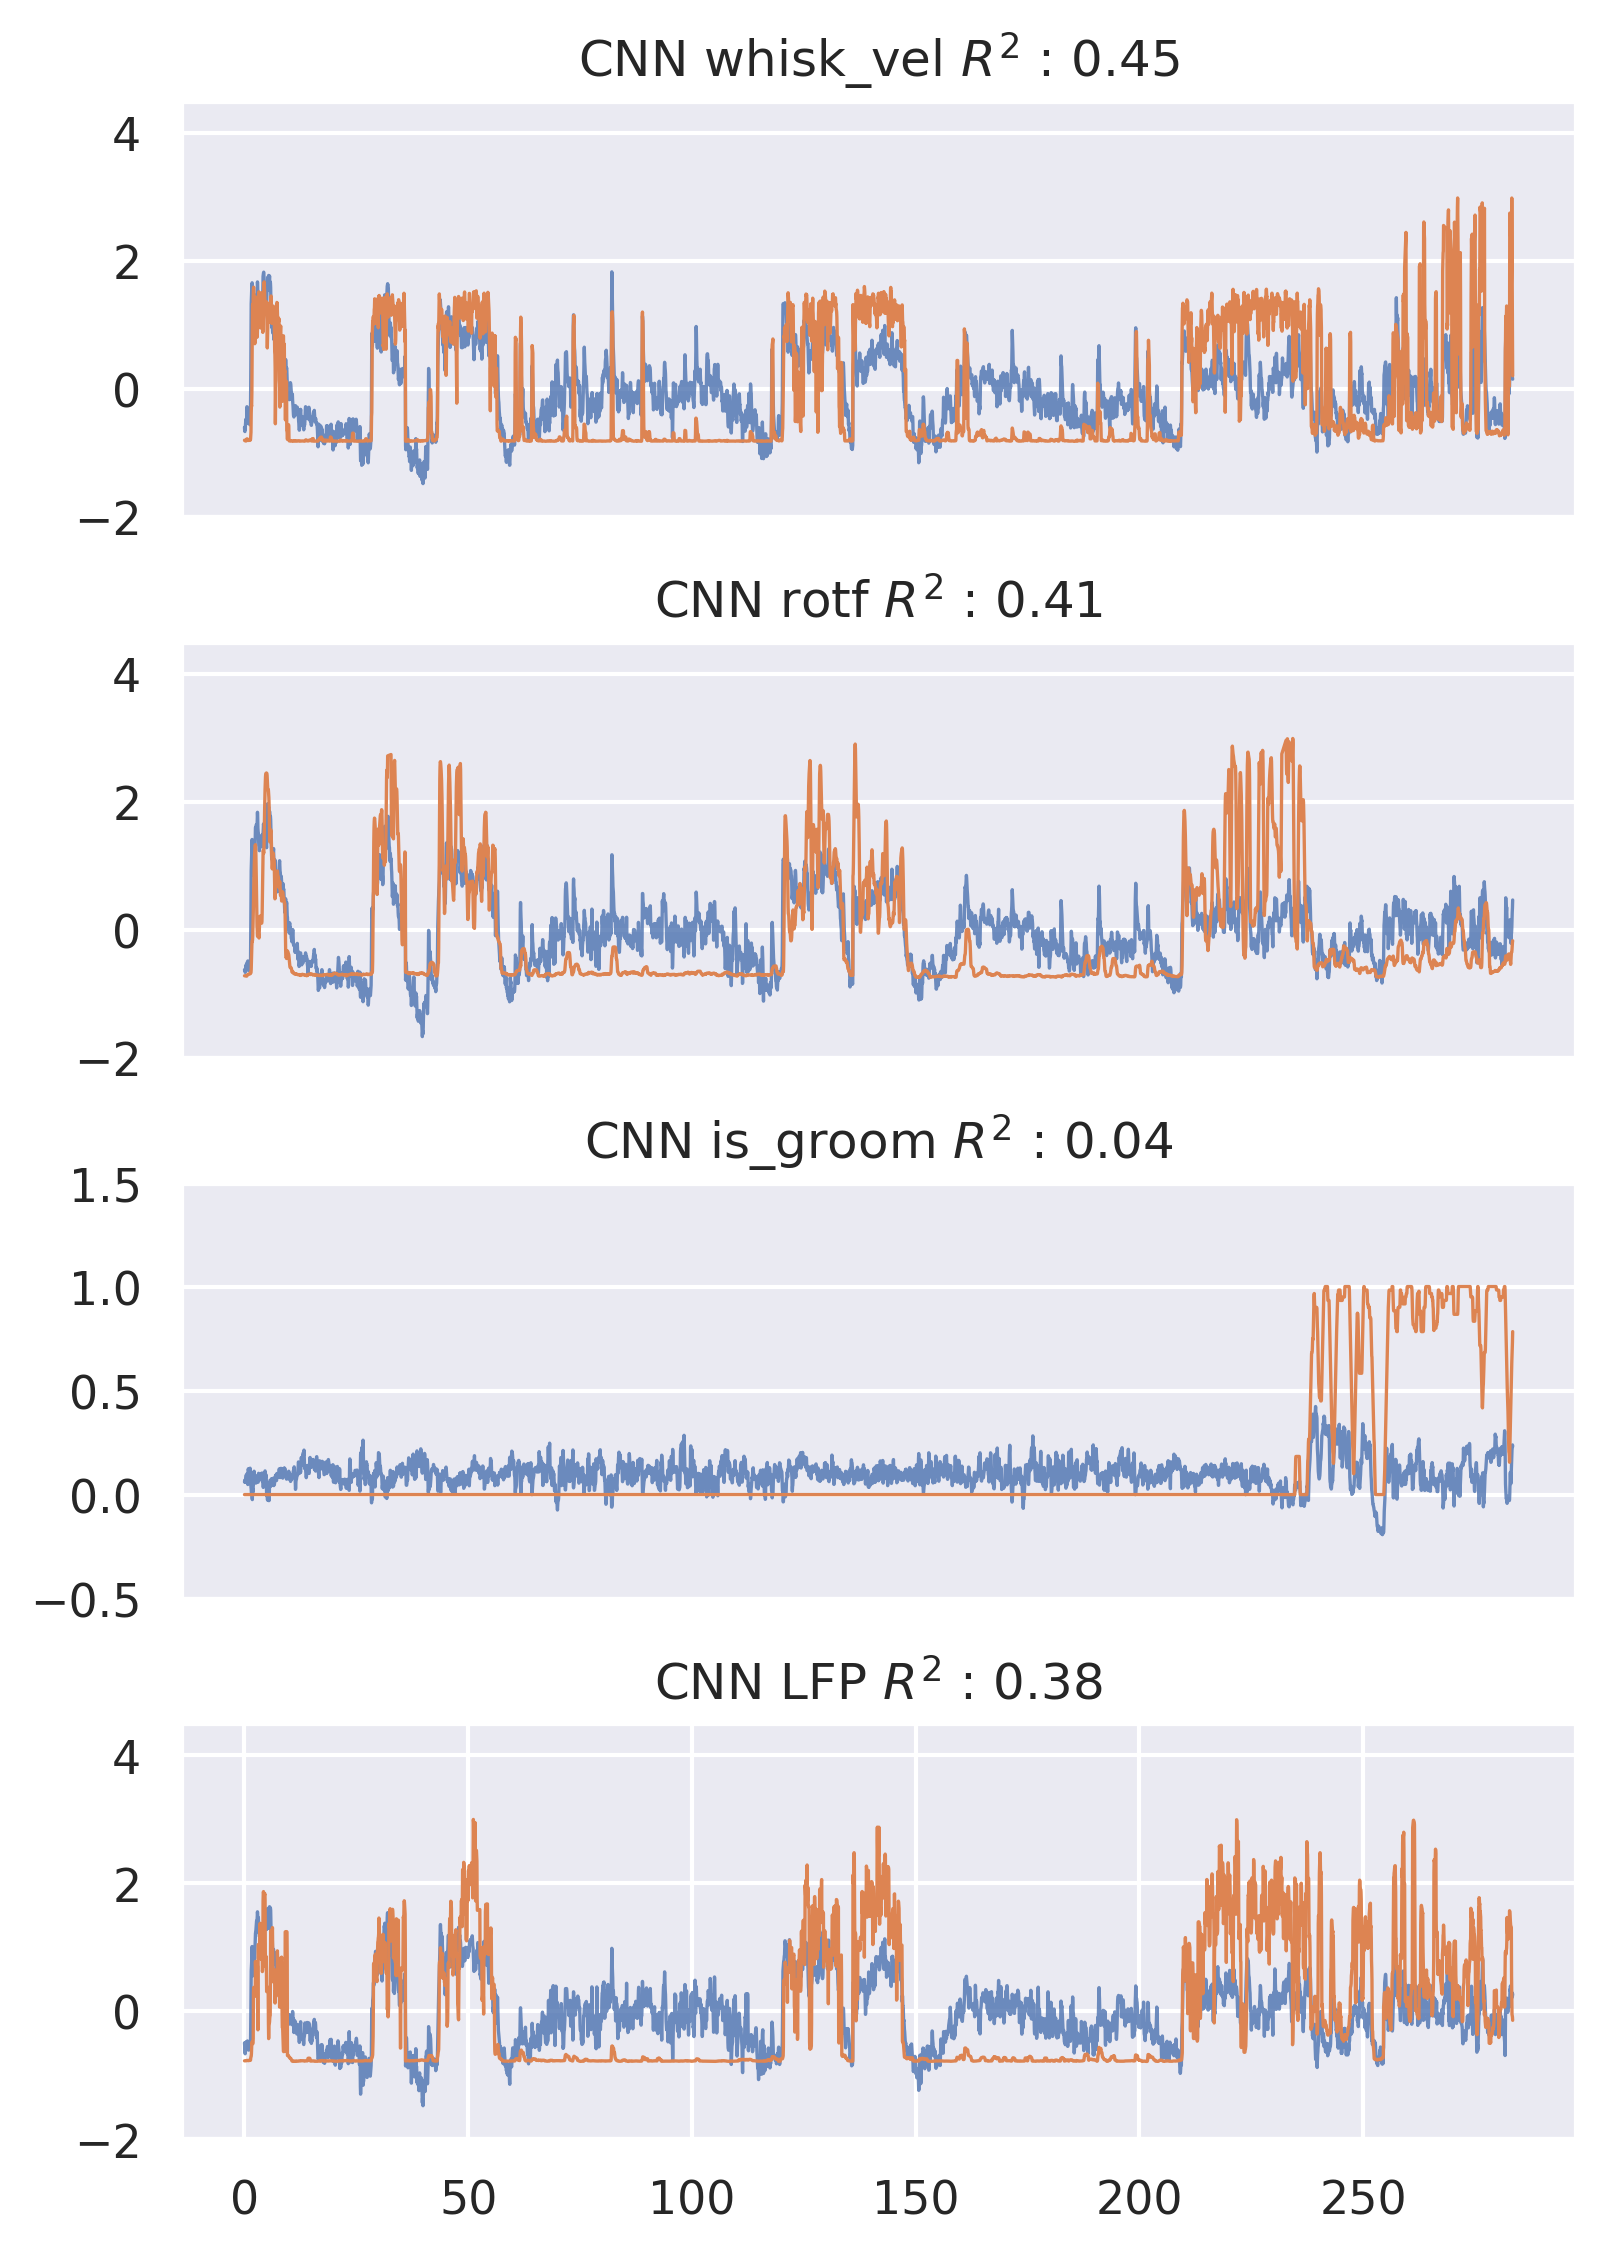

In [106]:
plt.figure(figsize=(6,9),dpi=300)
for i, name in enumerate(['whisk_vel', 'rotf', 'is_groom', 'LFP']):
    plt.subplot(4,1,i+1)
    t_range = np.r_[range(1280,2000),range(3000,5000),range(7000,8000),range(9000,10950)]
    t_ax = np.divide(range(len(t_range)),20)
    plt.plot(t_ax,y_predict[t_range,i],label='prediction',linewidth=0.8,alpha=0.8)
    plt.plot(t_ax,y[t_range,i],label='real test data',linewidth=0.8,alpha=1)


    r22 = r2_score(y[:,i],y_predict[:,i])
    if i+1<4:
        plt.xticks([])
    if name=='is_groom':
        plt.ylim([-0.5,1.5])
    else:
        plt.ylim([-2,4.5])
#     plt.legend()
    plt.title('CNN '+name+ ' $R^2$ : '+str(round(r22,2)))
plt.subplots_adjust(hspace=0.3)
# plt.savefig(save_path+'svgs/'+mouse+'_cnn_single_trial.svg', format='svg',dpi=300)
